# Python for Biological Data: pandas, seaborn, glob, NumPy

Notes and worked examples from what I have been learning in Python for bioinformatics.

**About the data:** all datasets below are small *made-up sample tables* (generated with a fixed random seed) so that every cell runs on its own. The protein names are only labels for the example. The values are not real measurements.

**Topics:** reading Excel files with pandas, grouped bar plots and box plots with seaborn, batch file handling with `glob`, and sequence comparison with NumPy.

In [21]:
%pip install seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [22]:
import glob
import os
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Colour palette used in the plots
colors = ['#7b4173', '#1f77b4', '#ff7f0e', '#2ca02c', '#e377c2']

## 1. Reading an Excel file into a pandas DataFrame

`pd.read_excel()` loads a sheet into a DataFrame. Here I first build a sample table, save it to an Excel file, and read it back, so the example does not depend on any outside file.

(Reading `.xlsx` files needs the `openpyxl` package: `pip install openpyxl`.)

In [23]:
rng = np.random.default_rng(42)

types = ['C-ferritin', 'XccFtnA', 'XccBfr', 'XccDps']
interfaces = ['IntA', 'IntB', 'IntC']
base_bsa = {'IntA': 2400, 'IntB': 1200, 'IntC': 900}   # made-up typical sizes

rows = []
for t in types:
    for i in interfaces:
        for _ in range(8):                               # 8 sample rows per combination
            bsa = rng.normal(base_bsa[i], 250)
            rows.append({
                'FerritinType': t,
                'InterfaceType': i,
                'BSA': round(bsa, 1),
                'InterfaceResidues': round(bsa / 35 + rng.normal(0, 3), 1),
                'InterfaceAtoms': round(bsa / 8 + rng.normal(0, 10), 1),
            })

sample_df = pd.DataFrame(rows)
sample_df.to_excel('sample_interfaces.xlsx', index=False)

# Read it back, exactly as you would read any Excel file
dataframe1 = pd.read_excel('sample_interfaces.xlsx')
dataframe1.head(10)

,FerritinType,InterfaceType,BSA,InterfaceResidues,InterfaceAtoms
0,C-ferritin,IntA,2476.2,67.6,317.0
1,C-ferritin,IntA,2635.1,69.4,316.4
2,C-ferritin,IntA,2432.0,68.5,303.8
3,C-ferritin,IntA,2186.7,65.1,281.1
4,C-ferritin,IntA,2416.5,72.4,306.7
5,C-ferritin,IntA,2185.2,63.5,263.6
6,C-ferritin,IntA,2619.6,74.7,325.6
7,C-ferritin,IntA,2229.8,67.4,277.2
8,C-ferritin,IntB,1092.9,30.2,141.9
9,C-ferritin,IntB,1291.4,38.1,165.7


In [24]:
print(dataframe1.columns)
print(dataframe1.shape)
dataframe1.describe()

Index(['FerritinType', 'InterfaceType', 'BSA', 'InterfaceResidues',
       'InterfaceAtoms'],
      dtype='str')
(96, 5)


,BSA,InterfaceResidues,InterfaceAtoms
count,96.000000,96.000000,96.000000
mean,1494.339583,42.657292,186.184375
std,670.763280,19.414844,84.131091
min,387.500000,10.900000,40.000000
25%,979.000000,28.375000,125.300000
50%,1253.300000,35.100000,156.250000
75%,2202.025000,63.050000,275.525000
max,2932.100000,81.300000,374.900000


## 2. Grouped bar plot with seaborn

A grouped bar plot compares a value across categories (`InterfaceType`) split by a second category (`FerritinType`, shown as the `hue`). `sns.move_legend()` places the legend neatly above the plot.

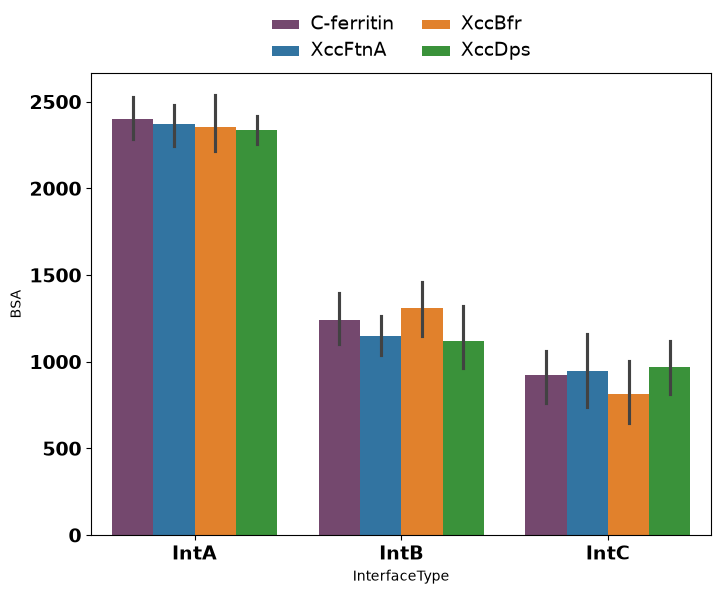

In [25]:
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=dataframe1, x='InterfaceType', y='BSA',
                 hue='FerritinType', palette=colors[:4])

sns.move_legend(ax, 'lower center', bbox_to_anchor=(.5, 1), ncol=2,
                title=None, frameon=False)
plt.setp(ax.get_legend().get_texts(), fontsize=14)
plt.yticks(fontsize=14, weight='bold')
plt.xticks(fontsize=14, weight='bold')
plt.ylabel('BSA')
plt.show()

## 3. Grouped box plot

A box plot shows the spread of the data (median, quartiles, range) rather than just the mean. `showfliers=False` hides outlier points and `width` controls box width.

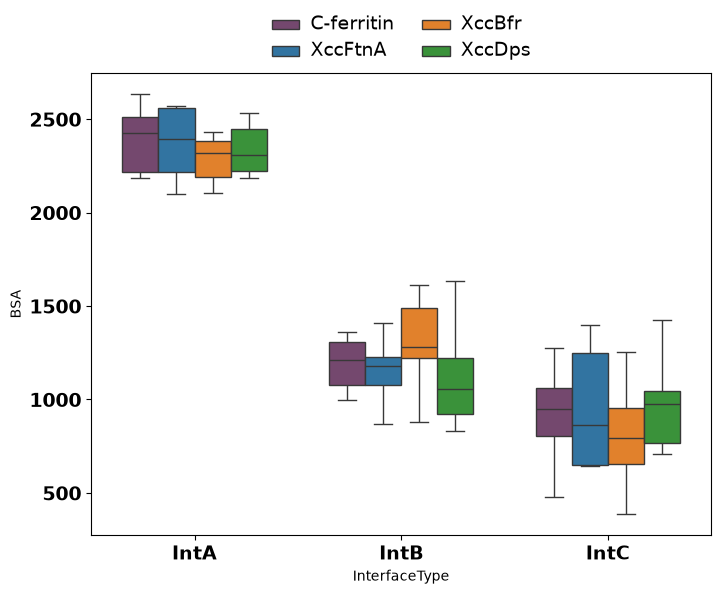

In [26]:
plt.figure(figsize=(8, 6))
ax = sns.boxplot(data=dataframe1, x='InterfaceType', y='BSA',
                 hue='FerritinType', palette=colors[:4],
                 showfliers=False, width=0.7)

sns.move_legend(ax, 'lower center', bbox_to_anchor=(.5, 1), ncol=2,
                title=None, frameon=False)
plt.setp(ax.get_legend().get_texts(), fontsize=14)
plt.yticks(fontsize=14, weight='bold')
plt.xticks(fontsize=14, weight='bold')
plt.show()

## 4. Scatter plot and box plot of the same data

Looking at the same variable in two ways is useful: the scatter plot shows every point, the box plot summarises them. The sample data below is made up (three groups, with `Test` having only a few points).

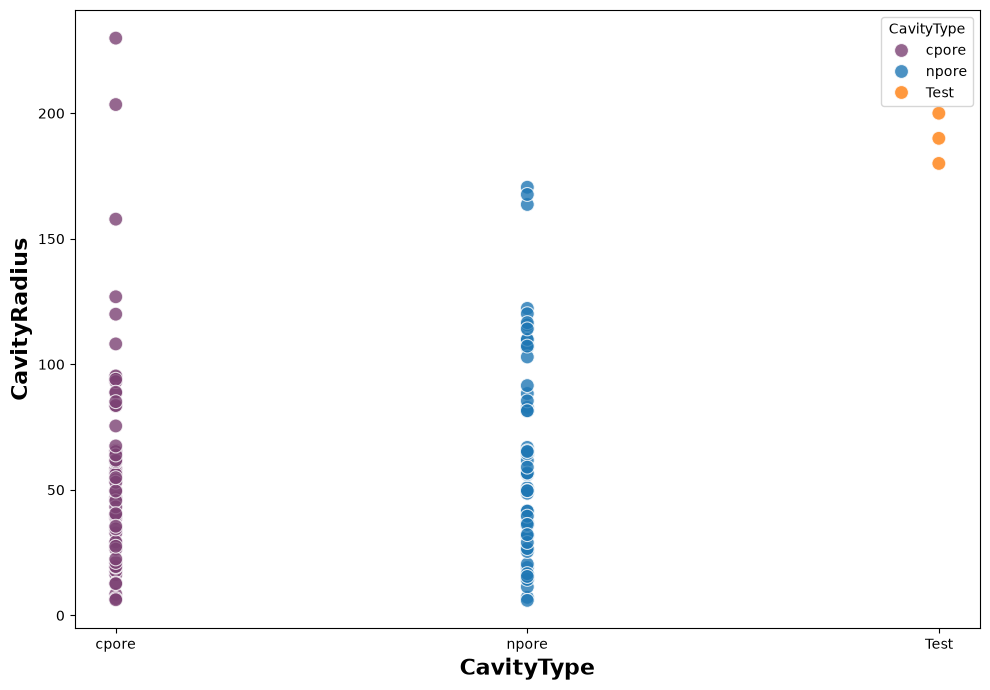

In [27]:
rng = np.random.default_rng(7)

cavity_df = pd.DataFrame({
    'CavityType': ['cpore'] * 60 + ['npore'] * 60 + ['Test'] * 3,
    'CavityRadius': np.concatenate([rng.gamma(2.0, 35, 60),
                                    rng.gamma(2.0, 38, 60),
                                    [180, 190, 200]]),
    'MinDist': np.concatenate([rng.normal(80, 40, 60).clip(5),
                               rng.normal(85, 40, 60).clip(5),
                               [150, 150, 150]]),
})

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=cavity_df, x='CavityType', y='CavityRadius',
                hue='CavityType', palette=colors[:3], s=100, alpha=0.8, ax=ax)
ax.set_xlabel('CavityType', fontsize=16, fontweight='bold')
ax.set_ylabel('CavityRadius', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

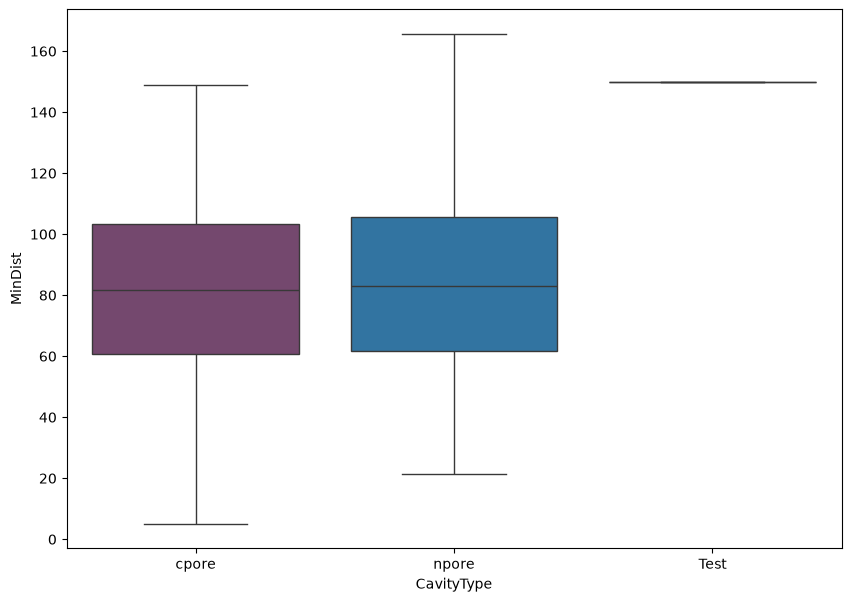

In [28]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=cavity_df, x='CavityType', y='MinDist',
            hue='CavityType', palette=colors[:3], ax=ax)
plt.show()

## 5. The `glob` module: batch file handling

`glob` is a built-in Python module that finds all file paths matching a pattern, using Unix-style wildcards. It is useful for processing many files in a loop, for example a folder of PDB structure files.

- `*` matches any number of characters
- `?` matches exactly one character

To keep this runnable anywhere, the example creates a few empty dummy files in a temporary folder and then finds them with a pattern.

In [29]:
# Create a temporary folder with some dummy files named like PDB files
folder = tempfile.mkdtemp()
for name in ['2cwl-ab.pdb', '2cwl-ac.pdb', '2cwl-ad.pdb', 'notes.txt']:
    open(os.path.join(folder, name), 'w').close()

# '????-??.pdb' = 4 characters, a dash, 2 characters, then .pdb
file_pattern = os.path.join(folder, '????-??.pdb')

for file in sorted(glob.glob(file_pattern)):
    try:
        print(os.path.basename(file))
        # In a real analysis you would read/process each file here
    except Exception:
        print('An exception occurred:', file)

2cwl-ab.pdb
2cwl-ac.pdb
2cwl-ad.pdb


In a real workflow, the loop body would read each structure file (for example with a library such as `biopandas`) and process it, so one script handles a whole folder.

## 6. NumPy for sequence comparison

NumPy arrays allow fast, vectorised comparison with no explicit loops. Turning a DNA string into an array of characters lets us compare two sequences base by base.

### Hamming distance
The Hamming distance is the number of positions at which two equal-length sequences differ.

In [30]:
s1 = np.array(list('ATGCGTTTATCT'))
s2 = np.array(list('ATGAGTTAATGC'))

distance = np.sum(s1 != s2)
print('Hamming distance:', distance)

Hamming distance: 4


### Finding mismatch positions
`np.where()` returns the indices where a condition is true. Adding 1 converts Python's 0-based index to the usual 1-based position used in sequence analysis.

In [31]:
ref = np.array(list('ATGCGTACCGTA'))
sample = np.array(list('ATGAGTACGGTA'))

positions = np.where(ref != sample)[0]
print([(int(p) + 1, str(ref[p]), str(sample[p])) for p in positions])
# Output format: (position, reference base, sample base)

[(4, 'C', 'A'), (9, 'C', 'G')]


## What I learned

- Loading tabular data from Excel with pandas and inspecting it (`head`, `columns`, `describe`)
- Making grouped bar plots and box plots with seaborn, and customising legends and fonts
- Choosing between a scatter plot (all points) and a box plot (spread) for the same data
- Processing many files at once with `glob`
- Comparing sequences with NumPy (Hamming distance, mismatch positions)